In [1]:
"""
MCMC de cosmic shear tomográfico sobre wl_pipeline.py (emcee).
  - Datos: vector de datos simulado en la cosmología fiducial (o el tuyo, ver DATA_FILE)
  - Covarianza: gaussiana, fija en la fiducial (calculada por wl_pipeline.run)
  - Teoría: se recalcula C_ell en cada paso con CCL, incluido el P(k) propio ("ccl" o "modified")
Uso:  OMP_NUM_THREADS=1 python mcmc_wl.py
"""
import os
import copy
import numpy as np
import pyccl as ccl
import emcee
from multiprocessing import Pool

import wl_pipeline as wl

In [2]:
# ---------------- Configuración ----------------
CFG = copy.deepcopy(wl.CFG)
COSMO = copy.deepcopy(wl.COSMO)

# nombre: (tipo, fiducial, min, max)   tipo = "cosmo" | "ia" | "pk"
# Para fijar un parámetro, quítalo de este dict (queda en su valor de CFG/COSMO).
PARAMS = {
    "Omega_c": ("cosmo", COSMO["Omega_c"], 0.10, 0.50),
    "sigma8":  ("cosmo", COSMO["sigma8"],  0.50, 1.20),
    "A_IA":    ("ia",    CFG["A_IA"],     -5.0,  5.0),
    "A_sup":   ("pk",    CFG["pk_pars"]["A_sup"], 0.0, 0.8),   # solo si pk_mode="modified"
}
DATA_FILE = None          # None -> datos simulados; si no, .npz con clave "dvec" (mismo orden que el pipeline)
NWALKERS_PER_DIM = 4
NSTEPS = 3000
NPROC = os.cpu_count()
OUT = "chain_wl.npz"

if CFG["pk_mode"] == "external":
    raise ValueError("pk_mode='external' usa un P(k) fijo que no responde a los parámetros "
                     "cosmológicos; para muestrear necesitas llamar a tu código/emulador en theory().")
if CFG["pk_mode"] != "modified":
    PARAMS = {n: p for n, p in PARAMS.items() if p[0] != "pk"}

NAMES = list(PARAMS)
FID = np.array([PARAMS[n][1] for n in NAMES])
LO = np.array([PARAMS[n][2] for n in NAMES])
HI = np.array([PARAMS[n][3] for n in NAMES])


In [5]:
if CFG["pk_mode"] == "modified" and "pk_pars" in CFG:
    PARAMS["A_sup"] = ("pk", CFG["pk_pars"]["A_sup"], 0.0, 0.8)
DATA_FILE = None          # None -> datos simulados; si no, .npz con clave "dvec" (mismo orden que el pipeline)
NWALKERS_PER_DIM = 4
NSTEPS = 3000
NPROC = os.cpu_count()
OUT = "chain_wl.npz"
 
if CFG["pk_mode"] == "external":
    raise ValueError("pk_mode='external' usa un P(k) fijo que no responde a los parámetros "
                     "cosmológicos; para muestrear necesitas llamar a tu código/emulador en theory().")
 
NAMES = list(PARAMS)
FID = np.array([PARAMS[n][1] for n in NAMES])
LO = np.array([PARAMS[n][2] for n in NAMES])
HI = np.array([PARAMS[n][3] for n in NAMES])
 
# ---------------- Setup (una vez) ----------------
fid = wl.run(CFG, COSMO)                      # n(z), ell, covarianza y vector de datos fiducial
Z, NZ_BINS, ELL, PAIRS = fid["z"], fid["nz_bins"], fid["ell"], fid["pairs"]
DATA = np.load(DATA_FILE)["dvec"] if DATA_FILE else fid["dvec"]
ICOV = np.linalg.inv(fid["cov"])


def theory(theta):
    """Vector de datos C_ell^{ij}(ell) para los parámetros theta."""
    cosmo_pars, cfg = dict(COSMO), copy.deepcopy(CFG)
    for name, val in zip(NAMES, theta):
        kind = PARAMS[name][0]
        if kind == "cosmo":
            cosmo_pars[name] = val
        elif kind == "ia":
            cfg["A_IA"] = val
        elif kind == "pk":
            cfg["pk_pars"][name] = val

    cosmo = ccl.Cosmology(**cosmo_pars, transfer_function=cfg["transfer"],
                          matter_power_spectrum="halofit")
    ia = (Z, cfg["A_IA"] * np.ones_like(Z)) if ("A_IA" in NAMES or cfg["A_IA"]) else None
    tracers = [ccl.WeakLensingTracer(cosmo, dndz=(Z, n), ia_bias=ia) for n in NZ_BINS]
    pk = wl.build_pk(cosmo, cfg, Z.max())
    return np.concatenate([ccl.angular_cl(cosmo, tracers[i], tracers[j], ELL, p_of_k_a=pk)
                           for i, j in PAIRS])


def log_prob(theta):
    if np.any(theta < LO) or np.any(theta > HI):   # priors planos
        return -np.inf
    try:
        r = DATA - theory(theta)
    except Exception:                               # errores de CCL (p.ej. fuera de rango)
        return -np.inf
    return -0.5 * r @ ICOV @ r


# ---------------- Muestreo ----------------
def main(nsteps=NSTEPS, nproc=NPROC):
    ndim = len(NAMES)
    nwalkers = NWALKERS_PER_DIM * ndim
    # inicio: bola pequeña alrededor de la fiducial, recortada a los priors
    p0 = FID + 1e-3 * (HI - LO) * np.random.randn(nwalkers, ndim)
    p0 = np.clip(p0, LO + 1e-6, HI - 1e-6)

    print(f"Parámetros: {NAMES}   pk_mode={CFG['pk_mode']}   walkers={nwalkers}")
    with Pool(nproc) as pool:
        sampler = emcee.EnsembleSampler(nwalkers, ndim, log_prob, pool=pool)
        sampler.run_mcmc(p0, nsteps, progress=True)

    tau = sampler.get_autocorr_time(tol=0)
    burn, thin = int(3 * tau.max()), max(1, int(tau.min() / 2))
    print("tau:", dict(zip(NAMES, np.round(tau, 1))),
          f"| NSTEPS/tau_max = {nsteps / tau.max():.0f} (se recomienda > 50)")
    flat = sampler.get_chain(discard=burn, thin=thin, flat=True)
    logp = sampler.get_log_prob(discard=burn, thin=thin, flat=True)
    print(f"Aceptación media: {sampler.acceptance_fraction.mean():.2f}")

    for n, col, f in zip(NAMES, flat.T, FID):
        lo, med, hi = np.percentile(col, [16, 50, 84])
        print(f"{n:>8s} = {med:.4f} +{hi - med:.4f} -{med - lo:.4f}   (fid {f:.4f})")
    if {"Omega_c", "sigma8"} <= set(NAMES):
        om = flat[:, NAMES.index("Omega_c")] + COSMO["Omega_b"]
        s8 = flat[:, NAMES.index("sigma8")] * np.sqrt(om / 0.3)
        lo, med, hi = np.percentile(s8, [16, 50, 84])
        print(f"{'S8':>8s} = {med:.4f} +{hi - med:.4f} -{med - lo:.4f}")

    np.savez(OUT, chain=flat, log_prob=logp, names=NAMES, fid=FID,
             full_chain=sampler.get_chain(), tau=tau)

    try:
        import corner
        fig = corner.corner(flat, labels=NAMES, truths=FID, show_titles=True,
                            quantiles=[0.16, 0.5, 0.84])
        fig.savefig("corner_wl.png", dpi=150)
    except ImportError:
        print("Instala 'corner' para el triangle plot.")

    return sampler


if __name__ == "__main__":
    main()


Parámetros: ['Omega_c', 'sigma8', 'A_IA', 'A_sup']   pk_mode=modified   walkers=16


Process SpawnPoolWorker-55:
Traceback (most recent call last):
  File "/opt/anaconda3/envs/nonlinear_pk/lib/python3.12/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
  File "/opt/anaconda3/envs/nonlinear_pk/lib/python3.12/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/opt/anaconda3/envs/nonlinear_pk/lib/python3.12/multiprocessing/pool.py", line 114, in worker
    task = get()
           ^^^^^
  File "/opt/anaconda3/envs/nonlinear_pk/lib/python3.12/multiprocessing/queues.py", line 389, in get
    return _ForkingPickler.loads(res)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^
AttributeError: Can't get attribute 'log_prob' on <module '__main__' (<class '_frozen_importlib.BuiltinImporter'>)>
Process SpawnPoolWorker-56:
Traceback (most recent call last):
  File "/opt/anaconda3/envs/nonlinear_pk/lib/python3.12/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
  File "/opt/anaconda3/envs/nonlinear_pk/lib/pyth

KeyboardInterrupt: 

In [7]:
import mcmc_wl
sampler = mcmc_wl.main()         

Parámetros: ['Omega_c', 'sigma8', 'A_IA', 'A_sup']   pk_mode=modified   walkers=16


You must install the tqdm library to use progress indicators with emcee


tau: {'Omega_c': 49.6, 'sigma8': 49.9, 'A_IA': 53.3, 'A_sup': 60.9} | NSTEPS/tau_max = 49 (se recomienda > 50)
Aceptación media: 0.55
 Omega_c = 0.2663 +0.0073 -0.0070   (fid 0.2664)
  sigma8 = 0.8310 +0.0099 -0.0096   (fid 0.8310)
    A_IA = -0.0021 +0.0308 -0.0297   (fid 0.0000)
   A_sup = 0.4059 +0.2663 -0.2675   (fid 0.2000)
      S8 = 0.8522 +0.0013 -0.0013
Instala 'corner' para el triangle plot.


In [8]:
import corner

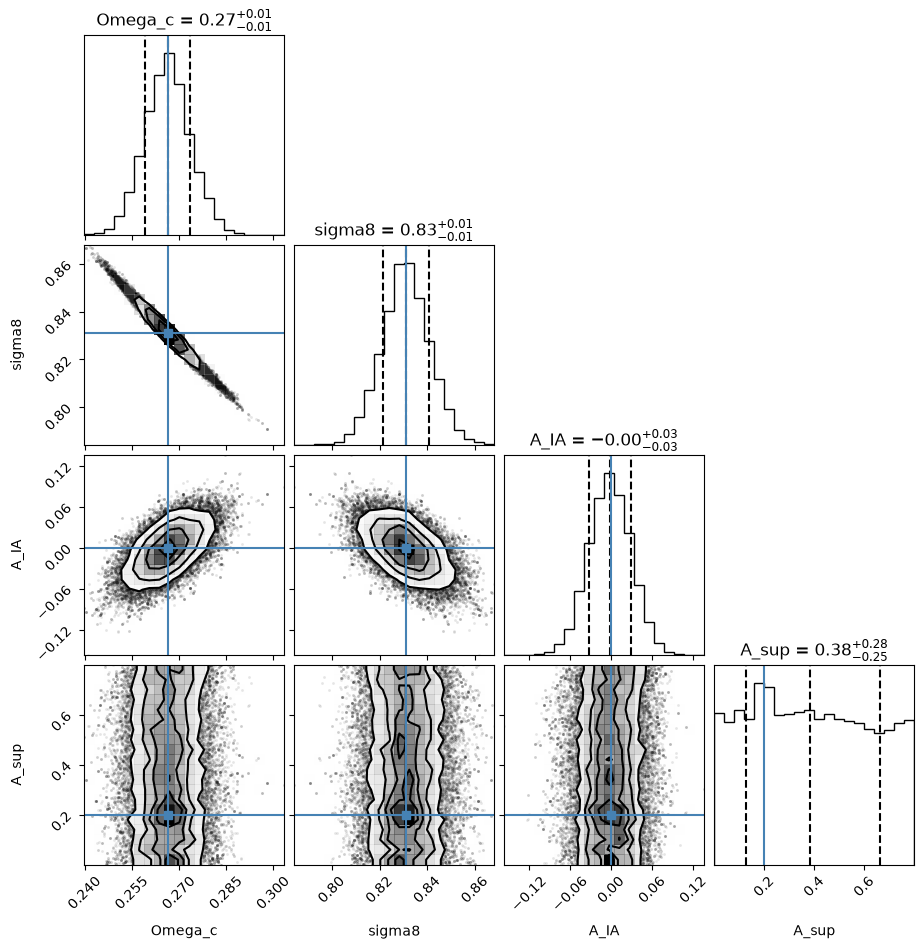

In [15]:
import corner
flat = sampler.get_chain(flat=True)
fig = corner.corner(flat, labels=NAMES, truths=FID, show_titles=True,
                            quantiles=[0.16, 0.5, 0.84])
#fig.savefig("corner_wl.png", dpi=150)
    